# Pre-entrega 3 — Clasificador supervisado con TF-IDF

**Proyecto Final — Data Science III (NLP & Deep Learning)** · Clasificación de noticias de AG News en 4 categorías: World, Sports, Business y Sci_Tech.

## Qué retomo y qué construyo

- **Del Módulo 1:** el repositorio, la separación entrenamiento / validación / test y la regla de elegir todo con validación y usar el test una sola vez.
- **Del Módulo 2 (Pre-entrega 2):** el corpus AG News y el preprocesamiento: limpieza con regex (entidades HTML, etiquetas, URLs, firmas de agencia), lematización con spaCy y deduplicación del train. Está en `src/pipeline/preprocesamiento.py`.
- **Nuevo en esta entrega:** vectorización con `TfidfVectorizer` (experimentando con `max_features` y `ngram_range`), tres clasificadores de referencia (Naive Bayes, SVM lineal y Regresión Logística) y evaluación con `classification_report` y matriz de confusión.

**Regla anti-fuga:** el `TfidfVectorizer` se ajusta **solo con el train** (`fit_transform`); a validación y test se les aplica `transform`. El modelo final es un `Pipeline` de scikit-learn, que lo garantiza solo.

**Cómo correrlo:** en Colab, *Entorno de ejecución → Ejecutar todas*. La primera celda clona el repositorio. Si los CSV de la cátedra (`ag_news_train.csv` y `ag_news_test.csv`) están en `data/ag_news/`, se usan esos; si no, se descarga la versión pública original de AG News (misma fuente, verificada con SHA-256). La primera corrida tarda unos 8 minutos, casi todo por spaCy; después el corpus procesado queda guardado.

## 1. Entorno

In [1]:
import subprocess
import sys
from pathlib import Path

REPO_URL = "https://github.com/BaltaGalelli/Pre-Entrega-3-.git"
EN_COLAB = "google.colab" in sys.modules


def encontrar_raiz():
    for carpeta in [Path.cwd(), *Path.cwd().parents]:
        if (carpeta / "src" / "pipeline").exists():
            return carpeta
    return None


raiz = encontrar_raiz()
if raiz is None and EN_COLAB:
    if not Path("Pre-Entrega-3-").exists():
        subprocess.run(["git", "clone", "-q", REPO_URL], check=True)
    raiz = Path("Pre-Entrega-3-").resolve()
if raiz is None:
    raise FileNotFoundError("No encuentro src/pipeline: ejecutá el notebook desde dentro del repositorio.")
if str(raiz / "src") not in sys.path:
    sys.path.insert(0, str(raiz / "src"))
print("Raíz del proyecto:", raiz, "| Colab:", EN_COLAB)

Raíz del proyecto: /tmp/claude-0/pe3/clon310 | Colab: False


In [2]:
import re
import time

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import sklearn
import spacy
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, classification_report, f1_score
from sklearn.model_selection import train_test_split
from sklearn.naive_bayes import MultinomialNB
from sklearn.svm import LinearSVC

from pipeline.ag_news import CLASES, preparar_corpus
from pipeline.clasico import (confusiones_principales, crear_modelos, crear_pipeline, crear_vectorizador, evaluar,
                              experimentar, graficar_experimentos, graficar_matriz_confusion, terminos_por_clase)
from pipeline.config import DIR_FIGURAS, DIR_REPORTES
from pipeline.preprocesamiento import clean_text, preprocess_text

SEMILLA = 42
DIR_FIGURAS.mkdir(parents=True, exist_ok=True)
pd.set_option("display.max_colwidth", 110)
print(f"Python {sys.version.split()[0]} | scikit-learn {sklearn.__version__} | spaCy {spacy.__version__} | pandas {pd.__version__}")

Python 3.10.20 | scikit-learn 1.6.1 | spaCy 3.8.7 | pandas 2.2.3


## 2. Datos y preprocesamiento (reutilizado de la Pre-entrega 2)

`preparar_corpus()` carga los splits oficiales, aplica el pipeline de la Pre-entrega 2 a train y test y deduplica **solo el train**: saca las noticias con etiquetas contradictorias, los duplicados y las noticias idénticas a una del test. Cada documento queda en tres versiones:

| Columna | Qué tiene | Para qué |
|---|---|---|
| `text` | la noticia original | referencia |
| `text_clean` | lemas en minúscula, con stop-words | modelos de secuencia (Módulo 4) |
| `text_nostop` | lemas sin stop-words (se conservan negaciones y "us") | **TF-IDF de esta entrega** |

In [3]:
t0 = time.time()
train, test, informe = preparar_corpus()
print(f"Listo en {time.time() - t0:.0f} s | fuente de los datos: {informe['fuente']}")
print(f"Train: {informe['inicial']:,} -> {informe['final']:,} noticias "
      f"(contradictorias: {informe['contradictorios']}, duplicadas: {informe['duplicados']}, iguales al test: {informe['iguales_al_test']}) | Test: {len(test):,} (intacto)")

ejemplo = "Stocks End Up, But Near Year Lows (Reuters) Reuters - Stocks ended slightly higher on Friday\\but stayed near lows for the year as oil prices surged past #36;46\\a barrel, offsetting a positive outlook from computer maker\\Dell Inc. (DELL.O)"
print("\nOriginal   :", ejemplo)
print("Regex      :", clean_text(ejemplo))
print("text_nostop:", preprocess_text(ejemplo, remove_stopwords=True))

Listo en 335 s | fuente de los datos: publico
Train: 120,000 -> 118,388 noticias (contradictorias: 284, duplicadas: 1166, iguales al test: 162) | Test: 7,600 (intacto)

Original   : Stocks End Up, But Near Year Lows (Reuters) Reuters - Stocks ended slightly higher on Friday\but stayed near lows for the year as oil prices surged past #36;46\a barrel, offsetting a positive outlook from computer maker\Dell Inc. (DELL.O)
Regex      : Stocks End Up, But Near Year Lows Stocks ended slightly higher on Friday but stayed near lows for the year as oil prices surged past $46 a barrel, offsetting a positive outlook from computer maker Dell Inc.
text_nostop: stock end near year lows stock end slightly high friday stay near low year oil price surge past 46 barrel offset positive outlook computer maker dell inc.


## 3. Separación de los datos

- **Test:** el split oficial de la cátedra (7.600 noticias, 1.900 por categoría). No se usa para elegir nada: se evalúa una sola vez, al final.
- **Validación:** el 10% del train, **estratificado** por categoría. Con ella se comparan todas las configuraciones.
- **Entrenamiento:** el 90% restante del train. Al final, la configuración ganadora se reentrena con el train completo.

In [4]:
tr, val = train_test_split(train, test_size=0.1, stratify=train["label"], random_state=SEMILLA)
resumen = pd.DataFrame({"entrenamiento": tr["label"].value_counts(), "validación": val["label"].value_counts(),
                        "test": test["label"].value_counts()}).reindex(CLASES)
resumen.loc["Total"] = resumen.sum()
display(resumen)

,entrenamiento,validación,test
label,,,
World,26798,2978,1900
Sports,26858,2984,1900
Business,26676,2964,1900
Sci_Tech,26217,2913,1900
Total,106549,11839,7600


## 4. Experimentos: `ngram_range` × `max_features` × modelo

Para cada configuración del vectorizador, el TF-IDF se ajusta **una vez y solo con el entrenamiento**, y la misma matriz se usa para los tres modelos (con sus parámetros por defecto). Parámetros fijos:

- `min_df=2`: un término tiene que aparecer en al menos 2 noticias. Saca errores de tipeo y palabras únicas, que no generalizan.
- `token_pattern=r"\S+"` y `lowercase=False`: el texto ya viene tokenizado y en minúsculas por spaCy; así se respetan sus tokens (incluidos los de una letra y los números, que el patrón por defecto descarta).
- Stop-words: ya se sacaron en el preprocesamiento (`text_nostop`), con una lista que conserva las negaciones.

**Métrica de selección:** F1 macro en validación (promedio del F1 de las 4 categorías, sin ponderar).

21 combinaciones en 114 s


,modelo,ngram_range,max_features,términos,memoria train (MB),accuracy val,F1 macro val,segundos
0,SVM lineal,"(1, 2)",sin límite,347631,44.8,0.9213,0.9210,2.9
1,SVM lineal,"(1, 2)",100000,100000,37.5,0.9164,0.9160,3.1
2,Regresión logística,"(1, 2)",100000,100000,37.5,0.9160,0.9156,9.1
3,Regresión logística,"(1, 2)",sin límite,347631,44.8,0.9153,0.9150,28.9
4,SVM lineal,"(1, 2)",30000,30000,32.1,0.9136,0.9133,2.4
5,SVM lineal,"(1, 1)",30000,30000,26.3,0.9129,0.9126,2.2
6,Regresión logística,"(1, 2)",30000,30000,32.1,0.9129,0.9126,4.5
7,SVM lineal,"(1, 1)",sin límite,35267,26.4,0.9122,0.9118,2.3
8,Regresión logística,"(1, 1)",30000,30000,26.3,0.9114,0.9111,5.0
9,Regresión logística,"(1, 1)",sin límite,35267,26.4,0.9113,0.9110,5.2


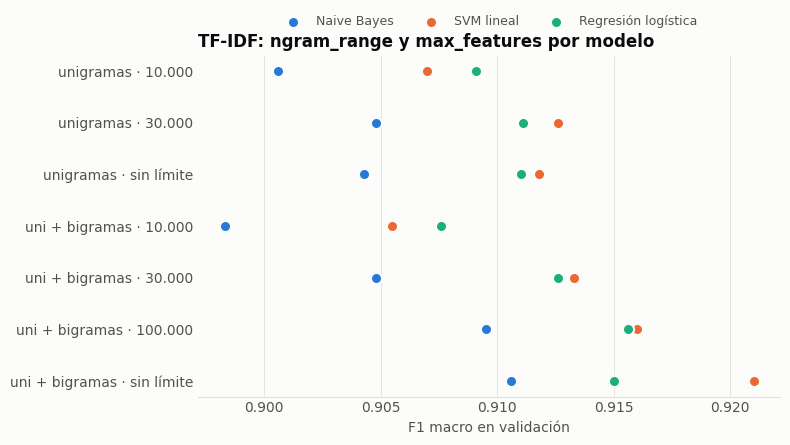

In [5]:
GRILLA = [{"ngram_range": (1, 1), "max_features": m} for m in (10_000, 30_000, None)] + \
         [{"ngram_range": (1, 2), "max_features": m} for m in (10_000, 30_000, 100_000, None)]

t0 = time.time()
resultados = experimentar(tr["text_nostop"], tr["label"], val["text_nostop"], val["label"], GRILLA, crear_modelos(SEMILLA))
print(f"{len(resultados)} combinaciones en {time.time() - t0:.0f} s")
resultados.to_csv(DIR_REPORTES / "pe3_experimentos.csv", index=False)
display(resultados.sort_values("F1 macro val", ascending=False).reset_index(drop=True))
graficar_experimentos(resultados, DIR_FIGURAS / "pe3_experimentos.png")
plt.show()

**Lo que muestra:**
- **El SVM lineal gana en casi todas las configuraciones** y Naive Bayes queda último en todas. La diferencia más grande aparece con todo el vocabulario de bigramas: ahí el SVM aprovecha mejor los cientos de miles de términos.
- **`ngram_range=(1, 2)`** ayuda solo si se deja un vocabulario grande. Con 10.000 o 30.000 términos, los bigramas compiten por el mismo cupo con unigramas útiles y no suman nada.
- **`max_features` no mejora la generalización:** limitar a 10.000 términos le cuesta más de 1 punto de F1 al SVM. Los modelos lineales ya tienen regularización, y `min_df=2` ya sacó los términos que aparecen una sola vez. Lo que sí hace `max_features` es reducir la memoria: con 100.000 bigramas la matriz ocupa 37,5 MB contra 44,8 MB, a cambio de 0,5 puntos de F1.

## 5. Ajuste de la regularización del mejor modelo

Con la mejor configuración del vectorizador, se prueba la regularización del modelo ganador (`C` en SVM y Regresión Logística, `alpha` en Naive Bayes). También en validación.

In [6]:
mejor = resultados.loc[resultados["F1 macro val"].idxmax()]
config_vec = {"ngram_range": (1, 2) if mejor["ngram_range"] == "(1, 2)" else (1, 1),
              "max_features": None if mejor["max_features"] == "sin límite" else int(mejor["max_features"])}
print("Mejor combinación:", mejor["modelo"], config_vec)

AJUSTE = {"SVM lineal": ("C", [0.1, 0.3, 1.0, 3.0], lambda v: LinearSVC(C=v, random_state=SEMILLA)),
          "Regresión logística": ("C", [1.0, 3.0, 10.0], lambda v: LogisticRegression(C=v, max_iter=1000, random_state=SEMILLA)),
          "Naive Bayes": ("alpha", [0.01, 0.1, 0.3, 1.0], lambda v: MultinomialNB(alpha=v))}
parametro, valores, constructor = AJUSTE[mejor["modelo"]]

vectorizador = crear_vectorizador(**config_vec)
X_tr = vectorizador.fit_transform(tr["text_nostop"])          # fit SOLO con el entrenamiento
X_val = vectorizador.transform(val["text_nostop"])
ajuste = {v: round(f1_score(val["label"], constructor(v).fit(X_tr, tr["label"]).predict(X_val), average="macro"), 4) for v in valores}
valor_elegido = max(ajuste, key=ajuste.get)
print(f"F1 macro en validación según {parametro}: {ajuste} -> elegido: {parametro} = {valor_elegido}")

Mejor combinación: SVM lineal {'ngram_range': (1, 2), 'max_features': None}


F1 macro en validación según C: {0.1: 0.9154, 0.3: 0.9201, 1.0: 0.921, 3.0: 0.9157} -> elegido: C = 1.0


## 6. ¿Hace falta el preprocesamiento? Texto crudo vs. limpio

Con la configuración ganadora, comparo cuatro entradas para el mismo modelo: el texto **crudo**, el texto solo con la **limpieza regex**, los **lemas con stop-words** y los **lemas sin stop-words**. Para el texto crudo y el regex uso la tokenización por defecto de scikit-learn (que además pasa a minúsculas).

In [7]:
modelo_elegido = lambda: constructor(valor_elegido)
tokenizacion_sklearn = {"token_pattern": r"(?u)\b\w\w+\b", "lowercase": True}
tr_regex, val_regex = tr["text"].map(clean_text), val["text"].map(clean_text)

entradas = {
    "texto crudo": (tr["text"], val["text"], tokenizacion_sklearn),
    "solo limpieza regex": (tr_regex, val_regex, tokenizacion_sklearn),
    "lemas con stop-words (text_clean)": (tr["text_clean"], val["text_clean"], {}),
    "lemas sin stop-words (text_nostop)": (tr["text_nostop"], val["text_nostop"], {}),
}
comparacion = pd.DataFrame({nombre: evaluar(x_tr, tr["label"], x_val, val["label"],
                                            crear_vectorizador(**config_vec, **extra), modelo_elegido())
                            for nombre, (x_tr, x_val, extra) in entradas.items()}).T
display(comparacion)

# ¿De dónde sale la ventaja del texto crudo? Las firmas de agencia y su categoría
fuente = test["text"].str.extract(r"\((Reuters|AP|AFP|Sports Network|NewsFactor|SPACE\.com|Ziff Davis|PC World|MacCentral|CBS\.MW)\)",
                                   expand=False).fillna("(sin firma)")
firmas = pd.crosstab(fuente, test["label"], normalize="index").mul(100).round(0).reindex(columns=CLASES)
firmas["noticias del test"] = fuente.value_counts()
display(firmas.sort_values("noticias del test", ascending=False))

,términos,accuracy val,F1 macro val
texto crudo,415564.0,0.9285,0.9281
solo limpieza regex,407843.0,0.9209,0.9205
lemas con stop-words (text_clean),382217.0,0.9180,0.9176
lemas sin stop-words (text_nostop),347631.0,0.9213,0.9210


label,World,Sports,Business,Sci_Tech,noticias del test
text,,,,,
(sin firma),22.0,26.0,25.0,27.0,5941
Reuters,32.0,12.0,41.0,14.0,776
AP,38.0,38.0,3.0,21.0,526
AFP,74.0,5.0,12.0,10.0,195
Sports Network,0.0,100.0,0.0,0.0,78
CBS.MW,3.0,0.0,89.0,9.0,35
NewsFactor,0.0,0.0,5.0,95.0,22
SPACE.com,0.0,0.0,0.0,100.0,9
PC World,0.0,0.0,0.0,100.0,8


**Lo que muestra:**
- **El texto crudo da el mejor número, pero por la razón equivocada.** La limpieza regex sola (sin lematizar) da casi lo mismo que los lemas: la ventaja del texto crudo no viene de "no lematizar", sino del **ruido que la limpieza saca**. Las firmas de agencia delatan la categoría: "(Sports Network)" aparece solo en Sports, "(NewsFactor)" o "(SPACE.com)" en Sci_Tech, y "(AFP)" sobre todo en World. Un modelo entrenado con ellas aprende a reconocer **la agencia**, no el tema, y en una noticia sin firma (o de otra fuente) ese atajo no existe. Por eso me quedo con el texto limpio, aunque cueste unas décimas en este test.
- **Las stop-words:** sacarlas (con la lista de spaCy, conservando las negaciones) deja 347.631 términos en lugar de 382.217 y el F1 hasta mejora un poco (0,921 contra 0,918). En una tarea **temática** las palabras funcionales casi no aportan; en Banking77, donde "not", "why" o "how" definen la intención, era al revés.
- **No todo el ruido salió:** "(CBS.MW)", la firma de CBS MarketWatch, no estaba en la lista de agencias de la Pre-entrega 2 y en el test marca Business el 89% de las veces. Lo retomo en la sección 8.

## 7. Modelo final y evaluación en el test

La configuración ganadora se reentrena con **todo el train** (entrenamiento + validación) dentro de un `Pipeline`: el `fit` ajusta el TF-IDF solo con el train y `predict` sobre el test aplica `transform`. Es la **única** vez que se usa el test.

In [8]:
final = crear_pipeline(crear_vectorizador(**config_vec), constructor(valor_elegido))
t0 = time.time()
final.fit(train["text_nostop"], train["label"])
pred = final.predict(test["text_nostop"])
print(f"Modelo: {mejor['modelo']} ({parametro}={valor_elegido}) | TF-IDF {config_vec} | "
      f"{len(final.named_steps['tfidf'].vocabulary_):,} términos | entrenado en {time.time() - t0:.0f} s\n")
print(classification_report(test["label"], pred, labels=CLASES, digits=4))
acc_test, f1_test = accuracy_score(test["label"], pred), f1_score(test["label"], pred, average="macro")
print(f"F1 macro: validación {ajuste[valor_elegido]:.4f} | test {f1_test:.4f} (diferencia: {ajuste[valor_elegido] - f1_test:+.4f})")

Modelo: SVM lineal (C=1.0) | TF-IDF {'ngram_range': (1, 2), 'max_features': None} | 383,945 términos | entrenado en 10 s

              precision    recall  f1-score   support

       World     0.9338    0.9053    0.9193      1900
      Sports     0.9581    0.9874    0.9725      1900
    Business     0.8856    0.8842    0.8849      1900
    Sci_Tech     0.8944    0.8958    0.8951      1900

    accuracy                         0.9182      7600
   macro avg     0.9180    0.9182    0.9180      7600
weighted avg     0.9180    0.9182    0.9180      7600

F1 macro: validación 0.9210 | test 0.9180 (diferencia: +0.0030)


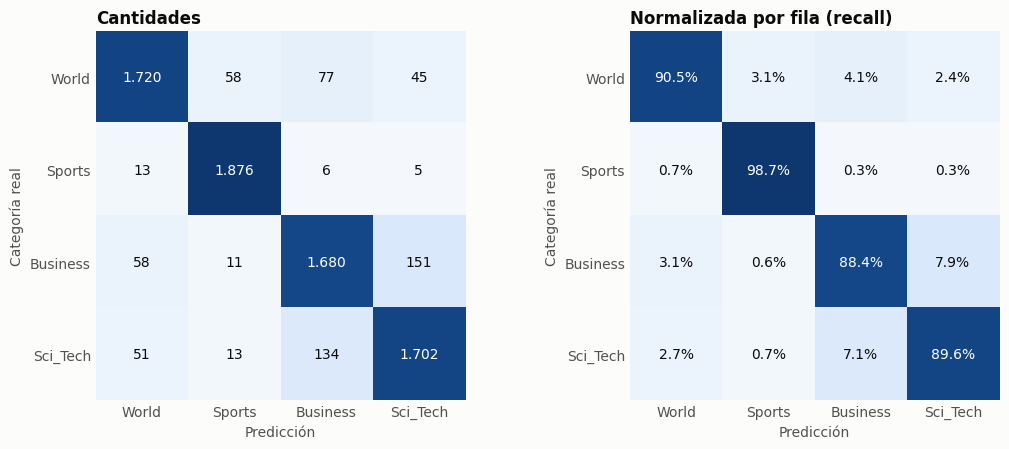

,real,predicha,errores,% de la clase real
0,Business,Sci_Tech,151,7.9
1,Sci_Tech,Business,134,7.1
2,World,Business,77,4.1
3,World,Sports,58,3.1
4,Business,World,58,3.1


In [9]:
fig, matriz = graficar_matriz_confusion(test["label"], pred, CLASES, DIR_FIGURAS / "pe3_matriz_confusion.png")
plt.show()
display(confusiones_principales(matriz, CLASES))

## 8. ¿Qué aprendió el modelo y dónde se equivoca?

Los términos con más peso hacia cada categoría (coeficientes del modelo lineal) y algunos errores reales del test.

In [10]:
display(terminos_por_clase(final, n=12))

errores = test.assign(prediccion=pred)[lambda d: d["label"] != d["prediccion"]]
for (real, predicha), _ in confusiones_principales(matriz, CLASES, n=2).set_index(["real", "predicha"]).iterrows():
    print(f"\n--- Real: {real} -> Predicho: {predicha} ---")
    for texto in errores[(errores["label"] == real) & (errores["prediccion"] == predicha)]["text"].head(4):
        print("·", clean_text(texto)[:170])

,Business,Sci_Tech,Sports,World
0,cbs.mw,nasa,coach,iraq
1,enron,internet,team,york stocks
2,tax,-washingtonpost.com,cup,u.s
3,martha,space,player,arafat
4,economy,software,nascar,iraqi
5,oil,scientist,baseball,hostage
6,bank,linux,nhl,athens greece
7,dow,web,quarterback,palestinian
8,insurance,-the washington,stadium,nuclear
9,insurer,science,season,troop



--- Real: Business -> Predicho: Sci_Tech ---
· Intel to delay product aimed for high-definition TVs SAN FRANCISCO -- In the latest of a series of product delays, Intel Corp. has postponed the launch of a video display
· Yahoo! Ups Ante for Small Businesses Web giant Yahoo! is gambling that price cuts on its domain name registration and Web hosting products will make it more competitive w
· Clicking on Profits The latest data from the US Department of Commerce further bolsters what we have all suspected: E-commerce sales are increasing. Not only might one su
· Amazon Snaps Up China's Largest Web Retailer Amazon.com (Nasdaq: AMZN) has said it will buy Joyo.com Limited -- a British Virgin Islands company that operates the largest

--- Real: Sci_Tech -> Predicho: Business ---
· IBM to hire even more new workers By the end of the year, the computing giant plans to have its biggest headcount since 1991.
· Some People Not Eligible to Get in on Google IPO Google has billed its IPO as a way fo

**Lo que muestra:**
- **La mayoría de los términos tiene sentido temático:** *nasa*, *software*, *linux* para Sci_Tech; *coach*, *nascar*, *quarterback* para Sports; *enron*, *tax*, *insurance* para Business; *iraq*, *arafat*, *hostage* para World.
- **Quedaron atajos que la limpieza no sacó:** *cbs.mw* (la firma de CBS MarketWatch, 94% Business en el train) y *-washingtonpost.com* / *-the washington* (firmas de notas de tecnología del Washington Post). Es la mejora concreta para la próxima versión del preprocesamiento.
- **Encabezados de ciudad (*datelines*):** *athens greece* (los Juegos Olímpicos de 2004) y *york stocks* ("NEW YORK - Stocks rose..."). Este último está en World: AG News etiquetó como World notas de la bolsa, que temáticamente son Business. Es **ruido en las etiquetas** del dataset.
- **Los errores de Business ↔ Sci_Tech son ambiguos de verdad:** Intel que demora un producto, Yahoo que baja precios o Amazon que compra una empresa son noticias de negocios **de empresas tecnológicas**; IBM contratando gente o la salida a bolsa de Google están etiquetadas como Sci_Tech. Ni siquiera un humano coincidiría siempre con la etiqueta.

In [11]:
import json

metricas = {
    "corpus": {k: (int(v) if isinstance(v, (int, float, np.integer)) else v) for k, v in informe.items()},
    "modelo": mejor["modelo"], parametro: valor_elegido,
    "vectorizador": {"ngram_range": list(config_vec["ngram_range"]), "max_features": config_vec["max_features"], "min_df": 2,
                     "terminos": len(final.named_steps["tfidf"].vocabulary_)},
    "validacion": {"F1 macro": float(ajuste[valor_elegido])},
    "test": {"accuracy": round(float(acc_test), 4), "F1 macro": round(float(f1_test), 4),
             "reporte": classification_report(test["label"], pred, labels=CLASES, output_dict=True)},
    "matriz_confusion": {"clases": CLASES, "valores": matriz.tolist()},
    "comparacion_entradas": comparacion.to_dict(orient="index"),
}
(DIR_REPORTES / "pe3_metricas.json").write_text(json.dumps(metricas, ensure_ascii=False, indent=1))
print("Guardado en reports/: pe3_experimentos.csv, pe3_metricas.json y las figuras")

Guardado en reports/: pe3_experimentos.csv, pe3_metricas.json y las figuras


## 9. Conclusiones

Las conclusiones, con los números de esta corrida, están en el `README.md` del repositorio: la justificación del modelo y de los parámetros del vectorizador, el análisis de la matriz de confusión y los próximos pasos.